In [ ]:
import pandas as pd

try:
    df_daily_max = pd.read_csv('/daily_max.csv')
    df_monthly_avg = pd.read_csv('/monthly_average.csv')
except FileNotFoundError as e:
    print("LỖI: Không tìm thấy file. Hãy đảm bảo file đã được đổi tên thành 'daily_max.csv' và 'monthly_avg.csv' và được đặt trong thư mục gốc của Colab.")
    print(f"Chi tiết lỗi: {e}")
    exit()

# --- CHUẨN HÓA DỮ LIỆU DAILY MAX VỀ MONTHLY AVERAGE ---

df_daily_max['Date'] = pd.to_datetime(df_daily_max['Date'])
df_daily_max = df_daily_max.set_index('Date')

df_monthly_max_avg = df_daily_max['Daily_Global_City_Max_Temp_C'].resample('M').mean().reset_index()

df_monthly_max_avg['Year'] = df_monthly_max_avg['Date'].dt.year
df_monthly_max_avg['Month'] = df_monthly_max_avg['Date'].dt.month

df_monthly_max_avg = df_monthly_max_avg.rename(
    columns={'Daily_Global_City_Max_Temp_C': 'Monthly_Avg_of_Daily_Max_Temp_C'}
)

df_merged = pd.merge(
    df_monthly_avg,
    df_monthly_max_avg[['Year', 'Month', 'Monthly_Avg_of_Daily_Max_Temp_C']],
    on=['Year', 'Month'],
    how='inner'
)

print(df_merged.head().to_markdown(index=False, numalign="left", stralign="left"))

| Year   | Month   | Monthly_Global_City_Avg_Temp_C   | Monthly_Avg_of_Daily_Max_Temp_C   |
|:-------|:--------|:---------------------------------|:----------------------------------|
| 1995   | 1       | 7.66                             | 30.0216                           |
| 1995   | 2       | 8.81                             | 30.4096                           |
| 1995   | 3       | 11.9                             | 32.4103                           |
| 1995   | 4       | 14.85                            | 34.621                            |
| 1995   | 5       | 18.76                            | 35.6219                           |


/tmp/ipython-input-2157951304.py:16: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_monthly_max_avg = df_daily_max['Daily_Global_City_Max_Temp_C'].resample('M').mean().reset_index()


In [ ]:
# --- TÍNH TOÁN HỆ SỐ TƯƠNG QUAN PEARSON ---

correlation_coefficient = df_merged['Monthly_Global_City_Avg_Temp_C'].corr(
    df_merged['Monthly_Avg_of_Daily_Max_Temp_C'],
    method='pearson'
)

print("\n---------------------------------------------------")
print("--- KẾT QUẢ TƯƠNG QUAN PEARSON (rho) ---")
print(f"Hệ số Tương quan Pearson (rho): {correlation_coefficient:.4f}")
print("---------------------------------------------------")


---------------------------------------------------
--- KẾT QUẢ TƯƠNG QUAN PEARSON (rho) ---
Hệ số Tương quan Pearson (rho): 0.9418
---------------------------------------------------


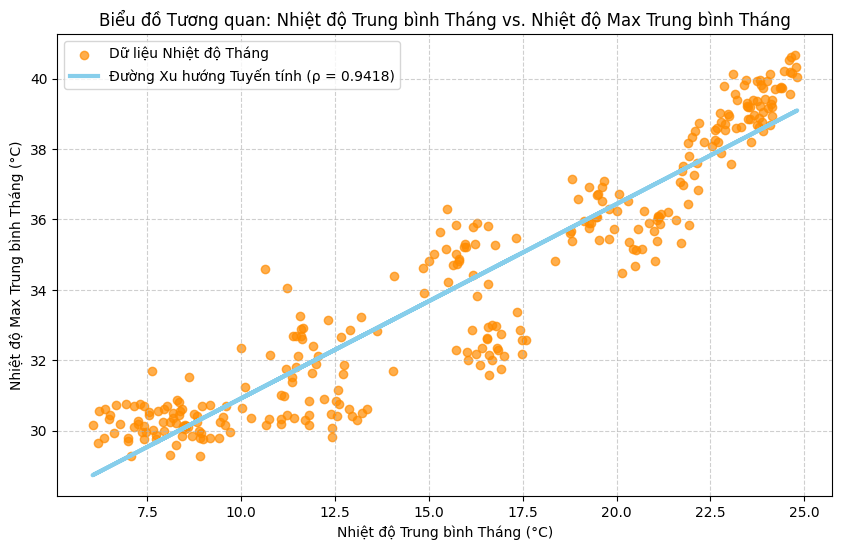

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

X = df_merged['Monthly_Global_City_Avg_Temp_C']
Y = df_merged['Monthly_Avg_of_Daily_Max_Temp_C']

m, b = np.polyfit(X, Y, 1)

plt.figure(figsize=(10, 6))

# Vẽ biểu đồ phân tán (Scatter Plot)
plt.scatter(X, Y, alpha=0.7, color='darkorange', label='Dữ liệu Nhiệt độ Tháng')

plt.plot(X, m*X + b, color='skyblue', linewidth=3,
         label=f'Đường Xu hướng Tuyến tính (ρ = {correlation_coefficient:.4f})')

plt.title(f'Biểu đồ Tương quan: Nhiệt độ Trung bình Tháng vs. Nhiệt độ Max Trung bình Tháng')
plt.xlabel('Nhiệt độ Trung bình Tháng (°C)')
plt.ylabel('Nhiệt độ Max Trung bình Tháng (°C)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()